<a href="https://colab.research.google.com/github/Dark-Chocolate-66/U-Net-Convolutional-Networks-for-Biomedical-Image-Segmentation/blob/main/U_net.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Environment Setup

In [ ]:
# Connect to Drive
from google.colab import drive
drive.mount('/content/drive')

# Download the ISBI Dataset
!mkdir -p /content/drive/MyDrive/unet_project/data
%cd /content/drive/MyDrive/unet_project/data
!wget -O ISBI-2012-challenge.zip https://downloads.imagej.net/ISBI-2012-challenge.zip
!unzip -q ISBI-2012-challenge.zip -d isbi2012
!ls isbi2012

# Download the Pet Dataset
from torchvision.datasets import OxfordIIITPet
pets = OxfordIIITPet(root="/content/data", split="trainval",
                     target_types="segmentation", download=True)
img, mask = pets[0]
print(img.size, mask.size)

Mounted at /content/drive
/content/drive/MyDrive/unet_project/data
--2026-10-20 07:33:41--  https://downloads.imagej.net/ISBI-2012-challenge.zip
Resolving downloads.imagej.net (downloads.imagej.net)... 144.92.48.183
Connecting to downloads.imagej.net (downloads.imagej.net)|144.92.48.183|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 31487579 (30M) [application/zip]
Saving to: ‘ISBI-2012-challenge.zip’

ISBI-2012-challenge 100%[===================>]  30.03M  17.8MB/s    in 1.7s    

2026-10-20 07:33:43 (17.8 MB/s) - ‘ISBI-2012-challenge.zip’ saved [31487579/31487579]

mapname:  conversion of  failed
replace isbi2012/test-volume.tif? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace isbi2012/test-labels.tif? [y]es, [n]o, [A]ll, [N]one, [r]ename: no
replace isbi2012/train-labels.tif? [y]es, [n]o, [A]ll, [N]one, [r]ename: [n]
error:  invalid response [[n]]
replace isbi2012/train-labels.tif? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace isbi2012/train-volume.tif? 

100%|██████████| 792M/792M [00:20<00:00, 39.3MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 15.5MB/s]


(394, 500) (394, 500)


Test Images

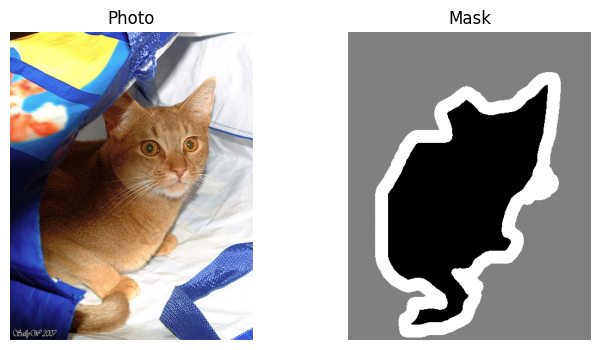

Mask values: [1 2 3]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

img, mask = pets[0]          # first photo and its mask
mask = np.array(mask)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img);                ax[0].set_title("Photo")
ax[1].imshow(mask, cmap="gray");  ax[1].set_title("Mask")
for a in ax: a.axis("off")
plt.show()

print("Mask values:", np.unique(mask))

In [ ]:
!pip install -q tifffile
import glob, tifffile

vol = glob.glob(f"{data_dir}/isbi2012/**/train-volume.tif", recursive=True)
lab = glob.glob(f"{data_dir}/isbi2012/**/train-labels.tif", recursive=True)
print(vol, lab)

images = tifffile.imread(vol[0])   # all 30 pictures
masks  = tifffile.imread(lab[0])   # their 30 masks
print(images.shape, masks.shape)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(images[0], cmap="gray"); ax[0].set_title("Cell image")
ax[1].imshow(masks[0],  cmap="gray"); ax[1].set_title("Mask")
for a in ax: a.axis("off")
plt.show()

NameError: name 'data_dir' is not defined